# N-BaIoT: centralized vs FedAvg vs FedProx (experiments E01–E18)

**What this notebook does.** It trains one intrusion-detection model on the same data in three ways: centrally, with **FedAvg**, and with **FedProx**. Every run is an **experiment** with its own number, goal and output folder.

| Experiment | What it is | Seeds | Goal |
|---|---|---|---|
| E01, E02 | Centralized, learning rate 0.003 / 0.01 | 1 each | Pick the centralized learning rate |
| E03 | Centralized, best learning rate | 3 | The reference. It sets the **target**: 99% of its final validation macro-F1 |
| E04 | FedAvg IID, Part 7 settings (E = 1, lr 0.01) | 3 | The cost of federating alone |
| E05 | FedAvg non-IID, Part 7 settings | 3 | The extra cost of real device differences |
| E06–E11 | FedAvg non-IID, E ∈ {1, 5, 10} × lr ∈ {0.003, 0.01} | 1 each | Find the best FedAvg setting |
| E12 | FedAvg non-IID, best setting | 3 | Final FedAvg result on non-IID clients |
| E13 | FedAvg IID, best setting | 3 | Does that setting also work for IID clients? |
| E14–E17 | FedProx non-IID, best FedAvg setting, μ = 0.001 / 0.01 / 0.1 / 1 | 1 each | Find the best μ |
| E18 | FedProx non-IID, best μ | 3 | Final FedProx result, to compare with E12 |

**Fixed for every experiment** (reasons and evidence: `claude/data-decisions-nbaiot.md`)
- **Data:** all 89 files, 105 features (the 10 clock columns removed), 10 classes (gafgyt tcp and udp merged), every repeated row kept.
- **Split:** each file by time: earliest 70% train, 1% gap, 15% validation, 1% gap, last 15% test. Test fingerprint `a96355dc304b417d`, the same as Parts 7 and 8.
- **Model:** MLP 105-64-32-10 (9,194 weights). **Training:** plain SGD, batch 64, no momentum. The same seed gives the same starting weights for every method.
- **Budget:** centralized 14 epochs; FedAvg and FedProx 60 rounds for every setting. The final model is the last epoch or round.
- **FL:** 9 clients (IID: 9 equal random shards; non-IID: one client per device), all clients every round, average weighted by client size, scaler built from the clients' sums, only weights sent during training.
- **Choosing "best":** the highest **validation** macro-F1 averaged over the last 5 epochs or rounds, picked by the code. The test set is logged for every experiment but never used to choose.
- **Reuse:** a run with the same setting and seed is trained once and reused (for example, E07 is E05's seed 0).

**How to run** (Jupyter on your PC)
1. Pick the kernel of the project's venv (Kernel → Change kernel). Cell 1 prints which Python it runs and the GPU it sees.
2. Have your Kaggle key at `C:\Users\<you>\.kaggle\kaggle.json`. Cell 2 downloads the data into `data/nbaiot` the first time.
3. Run all cells with `SMOKE_TEST = True` first (tiny data, a few minutes) to check that everything works. Then set `SMOKE_TEST = False`, restart the kernel and run all. The full run takes roughly 4–11 hours on an RTX 4090, depending on which number of local epochs wins (a bigger E makes E12–E18 cost more); every experiment prints an estimate before it starts.
4. If a run stops halfway, set `RUN_NAME` to its folder name and run all again: finished runs are loaded instead of trained again.

**Outputs** go to `results/<run name>/`: one folder per experiment (`E01_…` to `E18_…`) with CSV tables, PNG graphs, the log and the final weights, plus a summary of all experiments (section 8).

## 1. Settings
Everything you might want to change is in this cell.

In [1]:
# 1. Settings
import os, io, gc, sys, time, hashlib, datetime
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Image, display

SMOKE_TEST = False          # True = tiny data and few epochs/rounds, to check that everything runs (a few minutes)
RUN_NAME = None            # None = start a new run folder. To continue a stopped run, write its folder name here.

DATA_DIR = Path("data/nbaiot")       # the N-BaIoT CSV files (downloaded there the first time)
RESULTS_DIR = Path("results")        # one folder per run; inside it, one folder per experiment

# Data split: the same as Parts 7 and 8
TRAIN_FRAC, VAL_FRAC, GAP_FRAC = 0.70, 0.15, 0.01
EXPECTED_FINGERPRINT = "a96355dc304b417d"     # the test set of Parts 7 and 8
ROWS_PER_FILE = None                          # None = whole files

# Training
SEEDS = [0, 1, 2]              # seeds of the 3-seed experiments (a seed fixes the starting weights and the batch order)
DATA_SEED = 42                 # fixes the 9 IID shards (the same shards as Part 7)
BATCH_SIZE = 64
CENTRAL_EPOCHS = 14
ROUNDS = 60                    # every FedAvg and FedProx experiment
N_CLIENTS = 9

# What the searches try
CENTRAL_LRS = [0.003, 0.01]                                                                 # E01, E02
FEDAVG_SEARCH = [(1, 0.003), (1, 0.01), (5, 0.003), (5, 0.01), (10, 0.003), (10, 0.01)]    # E06-E11: (local epochs, lr)
FEDPROX_MUS = [0.001, 0.01, 0.1, 1.0]                                                       # E14-E17

# How results are judged
SELECT_LAST = 5                # "best" = highest validation macro-F1 averaged over the last 5 epochs or rounds
TARGET_SHARE = 0.99            # target = 99% of E03's final validation macro-F1 (mean over its seeds)

USE_CUDA_GRAPH = True          # fast GPU training: checks itself once and falls back to the plain loop if needed

if SMOKE_TEST:
    ROWS_PER_FILE, SEEDS, CENTRAL_EPOCHS, ROUNDS = 3000, [0], 2, 3

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cuda.matmul.allow_tf32 = False     # full float32 arithmetic (no TF32 shortcuts on the GPU)
torch.backends.cudnn.allow_tf32 = False

RUN_NAME = RUN_NAME or ("smoke_" if SMOKE_TEST else "run_") + datetime.datetime.now().strftime("%Y-%m-%d_%H%M")
RUN_DIR = RESULTS_DIR / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=True)
GPU_NAME = torch.cuda.get_device_name(0) if device.type == "cuda" else "none (CPU only)"

print("Python:", sys.executable)
print("torch", torch.__version__, "| CUDA build:", torch.version.cuda, "| GPU:", GPU_NAME)
print("results go to:", RUN_DIR.resolve(), "| smoke test:", SMOKE_TEST)
if device.type != "cuda":
    print("WARNING: PyTorch sees no GPU, so everything runs on the CPU (far too slow for the full run).")

LOG = {"file": None}           # the running experiment's log.txt

def log(*parts):
    """Print a line, and also add it to the running experiment's log.txt."""
    text = " ".join(str(p) for p in parts)
    print(text)
    if LOG["file"] is not None:
        with open(LOG["file"], "a", encoding="utf-8") as f:
            f.write(text + "\n")

def sync():
    """Wait until the GPU has finished its queued work, so that timings are real."""
    if device.type == "cuda":
        torch.cuda.synchronize()

Python: C:\Users\srb13\Desktop\fyp\.venv\Scripts\python.exe
torch 2.14.1+cu126 | CUDA build: 12.6 | GPU: NVIDIA RTX 4000 Ada Generation
results go to: C:\Users\srb13\Desktop\fyp\results\run_2026-11-09_2204 | smoke test: False


## 2. Get the data
Only the first time: the cell is skipped when the CSV files are already in `DATA_DIR`. It needs `pip install kaggle` and your Kaggle key (Kaggle → Settings → API → Create New Token) saved as `C:\Users\<you>\.kaggle\kaggle.json`.

In [2]:
# 2. Get the data (skipped if the CSV files are already there)
if not list(DATA_DIR.glob("*.benign.csv")):
    from kaggle.api.kaggle_api_extended import KaggleApi
    api = KaggleApi()
    api.authenticate()                       # reads C:\Users\<you>\.kaggle\kaggle.json
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    print("downloading mkashifn/nbaiot-dataset ...")
    api.dataset_download_files("mkashifn/nbaiot-dataset", path=str(DATA_DIR), unzip=True, quiet=False)
print(len(list(DATA_DIR.glob("*.csv"))), "csv files in", DATA_DIR.resolve())

92 csv files in C:\Users\srb13\Desktop\fyp\data\nbaiot


## 3. Load and split the data
Every file is read with the 105 features, labelled with its class, and split **by time**: its earliest 70% of rows go to training, then a 1% gap, the next 15% to validation, another 1% gap, and the last 15% to test. Each row also keeps its device (for the non-IID clients) and a fingerprint (to find test rows that also appear in training). The tables are saved in the run folder.

In [3]:
# 3. Load every file, drop the 10 clock columns, split each file by time, keep each row's device
TRAFFIC_TO_CLASS = {
    "benign": "benign",
    "gafgyt.combo": "gafgyt.combo",
    "gafgyt.junk": "gafgyt.junk",
    "gafgyt.scan": "gafgyt.scan",
    "gafgyt.tcp": "gafgyt.tcp_udp",     # identical rows once the clock is removed (decision 2) -> one class
    "gafgyt.udp": "gafgyt.tcp_udp",
    "mirai.ack": "mirai.ack",
    "mirai.scan": "mirai.scan",
    "mirai.syn": "mirai.syn",
    "mirai.udp": "mirai.udp",
    "mirai.udpplain": "mirai.udpplain",
}
CLASS_NAMES = list(dict.fromkeys(TRAFFIC_TO_CLASS.values()))     # benign is class 0
N_CLASSES = len(CLASS_NAMES)
CLASS_ID = {name: i for i, name in enumerate(CLASS_NAMES)}
SHORT = [c.replace("gafgyt.", "g.").replace("mirai.", "m.") for c in CLASS_NAMES]
DEVICE_NAMES = {1: "Danmini doorbell", 2: "Ecobee thermostat", 3: "Ennio doorbell", 4: "Philips baby monitor",
                5: "Provision PT-737E camera", 6: "Provision PT-838 camera", 7: "Samsung SNH-1011 webcam",
                8: "SimpleHome 1002 camera", 9: "SimpleHome 1003 camera"}
DEVICES = list(DEVICE_NAMES)

files = [(d, t, DATA_DIR / f"{d}.{t}.csv") for d in DEVICES for t in TRAFFIC_TO_CLASS
         if (DATA_DIR / f"{d}.{t}.csv").exists()]
assert len(files) == 89, f"expected 89 data files (devices 3 and 7 have no Mirai files), found {len(files)}"
ALL_COLUMNS = list(pd.read_csv(files[0][2], nrows=0).columns)
CLOCK_FEATURES = [c for c in ALL_COLUMNS if c.startswith("HH_jit_") and c.endswith(("_mean", "_variance"))]
FEATURES = [c for c in ALL_COLUMNS if c not in CLOCK_FEATURES]
N_FEATURES = len(FEATURES)
assert len(ALL_COLUMNS) == 115 and len(CLOCK_FEATURES) == 10 and N_FEATURES == 105

pieces = {s: {"X": [], "y": [], "dev": [], "hash": []} for s in ("train", "val", "test")}
report = []
t_start = time.time()
for i, (dev, traffic, path) in enumerate(files, 1):
    assert list(pd.read_csv(path, nrows=0).columns) == ALL_COLUMNS, f"columns differ in {path}"
    df = pd.read_csv(path, usecols=FEATURES, dtype=np.float32, nrows=ROWS_PER_FILE)[FEATURES]
    row_hash = pd.util.hash_pandas_object(df, index=False).to_numpy()   # one fingerprint per row
    X = df.to_numpy(dtype=np.float32)                                   # every row kept, in file order (= time order)
    del df
    n = len(X)
    a, b, gap = int(TRAIN_FRAC * n), int((TRAIN_FRAC + VAL_FRAC) * n), int(GAP_FRAC * n)
    blocks = {"train": slice(0, a), "val": slice(a + gap, b), "test": slice(b + gap, n)}
    label = CLASS_ID[TRAFFIC_TO_CLASS[traffic]]
    sizes = {}
    for split, rows in blocks.items():
        part = X[rows].copy()
        pieces[split]["X"].append(part)
        pieces[split]["y"].append(np.full(len(part), label, dtype=np.int64))
        pieces[split]["dev"].append(np.full(len(part), dev, dtype=np.int8))
        pieces[split]["hash"].append(row_hash[rows].copy())
        sizes[split] = len(part)
    report.append({"device": dev, "file": traffic, "class": CLASS_NAMES[label], "rows": n,
                   "repeated_rows": int(pd.Series(row_hash).duplicated().sum()),
                   "gap_rows": n - sum(sizes.values()), **sizes})
    del X
    if i % 10 == 0 or i == len(files):
        print(f"  {i}/{len(files)} files read ({time.time() - t_start:.0f} s)")

def join(split):
    out = tuple(np.concatenate(pieces[split][k]) for k in ("X", "y", "dev", "hash"))
    pieces[split] = None
    return out

X_train, y_train, dev_train, h_train = join("train")
X_val, y_val, dev_val, h_val = join("val")
X_test, y_test, dev_test, h_test = join("test")
del pieces
gc.collect()

report = pd.DataFrame(report)
data_table = report.groupby("class", sort=False)[["rows", "repeated_rows", "gap_rows", "train", "val", "test"]].sum()
data_table.loc["TOTAL"] = data_table.sum()
data_table["repeated %"] = (100 * data_table["repeated_rows"] / data_table["rows"]).round(1)
print(data_table.to_string())
print(f"\ntrain {len(y_train):,} | validation {len(y_val):,} | test {len(y_test):,} rows | "
      f"{N_FEATURES} features | {N_CLASSES} classes")
data_table.to_csv(RUN_DIR / "data_rows_per_class.csv")
report.to_csv(RUN_DIR / "data_rows_per_file.csv", index=False)

  10/89 files read (3 s)
  20/89 files read (5 s)
  30/89 files read (8 s)
  40/89 files read (11 s)
  50/89 files read (13 s)
  60/89 files read (16 s)
  70/89 files read (18 s)
  80/89 files read (20 s)
  89/89 files read (23 s)
                   rows  repeated_rows  gap_rows    train     val    test  repeated %
class                                                                                
benign           555932          42504     11112   389148   77834   77838         7.6
gafgyt.combo     515156              0     10294   360606   72126   72130         0.0
gafgyt.junk      261789              0      5226   183248   36656   36659         0.0
gafgyt.scan      255111              0      5090   178573   35723   35725         0.0
gafgyt.tcp_udp  1806216        1804370     36106  1264343  252878  252889        99.9
mirai.ack        643821              0     12866   450671   90140   90144         0.0
mirai.scan       537979              0     10750   376581   75322   75326        

## 4. Checks on the data
The clock columns are gone, every class is in every split, and the test set is exactly the one of Parts 7 and 8 (same fingerprint). The table of **test rows already seen in training** is needed to read the per-class scores (decision 4).

In [4]:
# 4. Checks on the data
largest = max(float(np.abs(X_train[i:i + 1_000_000]).max()) for i in range(0, len(X_train), 1_000_000))
print("1) Clock columns gone:", not (set(CLOCK_FEATURES) & set(FEATURES)),
      f"| largest |value| in training = {largest:.3g} (the clock values were about 1.5e9)")
print("2) Every class in every split:", all(len(np.unique(y)) == N_CLASSES for y in (y_train, y_val, y_test)))

PARTS_7_8 = {   # class: (rows, train, validation, test) in Parts 7 and 8
    "benign": (555932, 389148, 77834, 77838), "gafgyt.combo": (515156, 360606, 72126, 72130),
    "gafgyt.junk": (261789, 183248, 36656, 36659), "gafgyt.scan": (255111, 178573, 35723, 35725),
    "gafgyt.tcp_udp": (1806216, 1264343, 252878, 252889), "mirai.ack": (643821, 450671, 90140, 90144),
    "mirai.scan": (537979, 376581, 75322, 75326), "mirai.syn": (733299, 513306, 102665, 102668),
    "mirai.udp": (1229999, 860995, 172204, 172208), "mirai.udpplain": (523304, 366309, 73266, 73271)}
same_split = all(tuple(int(v) for v in data_table.loc[c, ["rows", "train", "val", "test"]]) == PARTS_7_8[c]
                 for c in CLASS_NAMES)
TEST_FINGERPRINT = hashlib.sha1(h_test.tobytes() + y_test.tobytes()).hexdigest()[:16]   # changes with the pandas version
print("3) Same rows per class in every split as Parts 7 and 8:", same_split, "| test fingerprint on this PC:", TEST_FINGERPRINT)
if ROWS_PER_FILE is None:
    assert same_split, "the split differs from Parts 7 and 8"

seen_test = np.isin(h_test, h_train)            # test rows whose exact values also appear in training
test_rows = np.bincount(y_test, minlength=N_CLASSES)
seen_table = pd.DataFrame({"test rows": test_rows,
                           "% seen in training": 100 * np.bincount(y_test, weights=seen_test, minlength=N_CLASSES) / test_rows},
                          index=CLASS_NAMES)
print("4) Test rows whose exact values also appear in training:")
print(seen_table.round(2).to_string())
seen_table.to_csv(RUN_DIR / "data_test_rows_seen_in_training.csv")

rows_per_device = pd.DataFrame({s: pd.Series(d).value_counts().sort_index()
                                for s, d in (("train", dev_train), ("validation", dev_val), ("test", dev_test))})
rows_per_device.index = [f"{d} {DEVICE_NAMES[d]}" for d in rows_per_device.index]
print("5) Rows per device:")
print(rows_per_device.to_string())
rows_per_device.to_csv(RUN_DIR / "data_rows_per_device.csv")

1) Clock columns gone: True | largest |value| in training = 6.37e+05 (the clock values were about 1.5e9)
2) Every class in every split: True
3) Same rows per class in every split as Parts 7 and 8: True | test fingerprint on this PC: bae248568b8cc3d8
4) Test rows whose exact values also appear in training:
                test rows  % seen in training
benign              77838               22.84
gafgyt.combo        72130                0.00
gafgyt.junk         36659                0.00
gafgyt.scan         35725                0.00
gafgyt.tcp_udp     252889               99.91
mirai.ack           90144                0.00
mirai.scan          75326                0.00
mirai.syn          102668                0.00
mirai.udp          172208                0.00
mirai.udpplain      73271                0.00
5) Rows per device:
                             train  validation    test
1 Danmini doorbell          712803      142568  142575
2 Ecobee thermostat         585107      117029  117034
3 

## 5. Building blocks
- **Model:** MLP 105-64-32-10 with ReLU. `get_weights` / `set_weights` turn its weights into one flat vector and back: that vector is what travels between clients and server.
- **Scaling:** every feature becomes (x − mean) / std, with the mean and std of the training rows.
- **`SGDTrainer`:** plain mini-batch SGD, one batch at a time: **w ← w − lr · (gradient of the batch loss + μ · (w − w_global))**. μ = 0 is plain SGD (centralized and FedAvg); μ > 0 is FedProx's local step (section 6).
  - *Speed on the GPU.* The model is tiny, so at batch 64 a GPU step spends most of its time on Python and on launching GPU kernels, not on arithmetic. On a GPU, one whole SGD step is recorded once as a **CUDA graph** and replayed for every full batch; the last, smaller batch of each epoch runs as a normal step. The arithmetic is the same. The first graph in the notebook is checked once against the plain loop (200 steps from the same start); if the two disagree, or Windows refuses the graph, every trainer uses the plain loop instead.
- **Scores:** from a confusion matrix: macro-F1 (the mean F1 of the classes present), accuracy, precision, recall and F1 per class, false alarm rate (benign rows called an attack) and detection rate (attack rows called any attack).
- **Charts** use one colour-blind-checked palette in a fixed order.

In [5]:
# 5. Building blocks: model, weights, scaling, SGD trainer, evaluation, scores, chart style
def make_model(seed):
    """MLP 105-64-32-10 with ReLU. The seed fixes the starting weights."""
    torch.manual_seed(seed)
    return nn.Sequential(
        nn.Linear(N_FEATURES, 64), nn.ReLU(),
        nn.Linear(64, 32), nn.ReLU(),
        nn.Linear(32, N_CLASSES),
    ).to(device)

N_PARAMS = sum(p.numel() for p in make_model(0).parameters())
print(f"model: {N_PARAMS:,} weights = {N_PARAMS * 4:,} bytes per copy (float32)")

def get_weights(model):
    """All weights as one flat float32 vector on the CPU: this is what goes on the wire."""
    return torch.cat([p.detach().reshape(-1) for p in model.parameters()]).cpu().clone()

def set_weights(model, vector):
    """Copy a flat weight vector into the model, in place (the model keeps the same tensors)."""
    vector = vector.to(device)
    start = 0
    with torch.no_grad():
        for p in model.parameters():
            p.copy_(vector[start:start + p.numel()].view_as(p))
            start += p.numel()
    assert start == len(vector)

def central_scaler(X, chunk=500_000):
    """Mean and std of the training rows, computed in float64 (two passes)."""
    n = len(X)
    mean = sum(X[i:i + chunk].sum(0, dtype=np.float64) for i in range(0, n, chunk)) / n
    sq_dev = sum(((X[i:i + chunk].astype(np.float64) - mean) ** 2).sum(0) for i in range(0, n, chunk))
    std = np.sqrt(sq_dev / n)
    std[std < 1e-8] = 1.0                 # constant feature: left unscaled (same rule as the server)
    return mean, std

def scale_to_device(X, mean, std, chunk=1_000_000):
    """(X - mean) / std in float32, built chunk by chunk straight on the device."""
    mean, std = np.asarray(mean, dtype=np.float32), np.asarray(std, dtype=np.float32)
    out = torch.empty(X.shape, dtype=torch.float32, device=device)
    for i in range(0, len(X), chunk):
        out[i:i + chunk] = torch.from_numpy((X[i:i + chunk] - mean) / std).to(device)
    return out


GRAPH = {"usable": USE_CUDA_GRAPH and device.type == "cuda", "checked": False, "max_difference": None}

def loop_name():
    return "CUDA graph" if GRAPH["usable"] else "plain loop"


class SGDTrainer:
    """Plain mini-batch SGD for one model, with the optional FedProx term.

    One step on one batch:   w  <-  w - lr * (gradient of the batch loss + mu * (w - w_global))
    mu = 0 is plain SGD. For FedProx, w_global is the global model the client received this round
    (stored by set_anchor), and mu * (w - w_global) is the gradient of (mu / 2) * ||w - w_global||^2.
    Each epoch goes through the rows in a random order drawn from the caller's generator.
    """
    def __init__(self, model, lr, batch_size, mu=0.0):
        self.model, self.lr, self.batch_size, self.mu = model, lr, batch_size, mu
        self.params = list(model.parameters())
        self.anchor = [p.detach().clone() for p in self.params]      # w_global (used only when mu > 0)
        self.graph = None

    def set_anchor(self):
        """FedProx: remember the current weights (the global model just received) as w_global."""
        with torch.no_grad():
            for a, p in zip(self.anchor, self.params):
                a.copy_(p)

    def step(self, xb, yb):
        """One SGD step on one batch."""
        loss = F.cross_entropy(self.model(xb), yb)
        grads = torch.autograd.grad(loss, self.params)
        with torch.no_grad():
            for p, g, a in zip(self.params, grads, self.anchor):
                if self.mu > 0:
                    g = g + self.mu * (p - a)          # FedProx: pull toward the global model
                p.add_(g, alpha=-self.lr)              # w <- w - lr * gradient

    def run_epoch(self, X, y, generator):
        """One pass over (X, y), in a random order drawn from the generator."""
        order = torch.randperm(len(X), generator=generator).to(X.device)
        n_full = len(X) - len(X) % self.batch_size                    # rows that fill whole batches
        if self.graph is None and n_full > 0 and X.is_cuda and GRAPH["usable"]:
            self.graph = self._record_graph(X, y)
        for start in range(0, n_full, self.batch_size):
            idx = order[start:start + self.batch_size]
            if self.graph is not None:
                torch.index_select(X, 0, idx, out=self.xb)            # put the batch where the graph reads it
                torch.index_select(y, 0, idx, out=self.yb)
                self.graph.replay()                                    # the recorded SGD step
            else:
                self.step(X[idx], y[idx])
        if n_full < len(X):                                            # the last, smaller batch: a normal step
            idx = order[n_full:]
            self.step(X[idx], y[idx])

    # ---- the CUDA graph (GPU only) ----
    def _record_graph(self, X, y):
        """Record one SGD step as a CUDA graph. Returns None (plain loop) if recording or the one-time check fails."""
        start = self._copy()
        try:
            self.xb, self.yb = X[:self.batch_size].clone(), y[:self.batch_size].clone()   # the graph's input slots
            side = torch.cuda.Stream()
            side.wait_stream(torch.cuda.current_stream())
            with torch.cuda.stream(side):              # CUDA graphs need a few normal steps first (warm-up)
                for _ in range(3):
                    self.step(self.xb, self.yb)
            torch.cuda.current_stream().wait_stream(side)
            graph = torch.cuda.CUDAGraph()
            with torch.cuda.graph(graph):               # recorded, not run
                self.step(self.xb, self.yb)
            self._restore(start)                        # undo the warm-up steps
            if not GRAPH["checked"]:
                GRAPH["checked"] = True
                diff = self._compare(graph, X, y)
                GRAPH["max_difference"] = diff
                if not diff <= 1e-4:
                    GRAPH["usable"] = False
                    log(f"CUDA graph check FAILED (max weight difference {diff:.2e}): using the plain loop from now on")
                    return None
                log(f"CUDA graph check passed: 200 graph steps = 200 plain steps (max weight difference {diff:.1e})")
            return graph
        except Exception as error:                      # e.g. CUDA graphs not supported on this setup
            GRAPH["usable"] = False
            sync()
            self._restore(start)
            log(f"CUDA graph not available ({type(error).__name__}: {error}); using the plain loop from now on")
            return None

    def _compare(self, graph, X, y, steps=200):
        """The same batches through the graph and through the plain step, from the same start: max weight difference."""
        start = self._copy()
        steps = min(steps, len(X) // self.batch_size)
        order = torch.randperm(len(X), generator=torch.Generator().manual_seed(12345)).to(X.device)
        batches = [order[k * self.batch_size:(k + 1) * self.batch_size] for k in range(steps)]
        for idx in batches:
            self.step(X[idx], y[idx])
        plain = self._copy()
        self._restore(start)
        for idx in batches:
            torch.index_select(X, 0, idx, out=self.xb)
            torch.index_select(y, 0, idx, out=self.yb)
            graph.replay()
        diff = max((p.detach() - q).abs().max().item() for p, q in zip(self.params, plain))
        self._restore(start)
        return diff

    def _copy(self):
        return [p.detach().clone() for p in self.params]

    def _restore(self, saved):
        with torch.no_grad():
            for p, s in zip(self.params, saved):
                p.copy_(s)


@torch.no_grad()
def evaluate(model, X, y, chunk=262_144):
    """Mean loss and confusion matrix (rows = true class, columns = predicted class)."""
    loss_sum = torch.zeros((), dtype=torch.float64, device=X.device)
    conf = torch.zeros(N_CLASSES * N_CLASSES, dtype=torch.long, device=X.device)
    for i in range(0, len(X), chunk):
        out, yb = model(X[i:i + chunk]), y[i:i + chunk]
        loss_sum += F.cross_entropy(out, yb, reduction="sum").double()
        conf += torch.bincount(yb * N_CLASSES + out.argmax(1), minlength=N_CLASSES * N_CLASSES)
    return loss_sum.item() / len(X), conf.view(N_CLASSES, N_CLASSES).cpu().numpy()

@torch.no_grad()
def predict(model, X, chunk=262_144):
    """The predicted class of every row (int8, on the CPU)."""
    return torch.cat([model(X[i:i + chunk]).argmax(1) for i in range(0, len(X), chunk)]).to(torch.int8).cpu().numpy()

def confusion(y_true, y_pred):
    """Confusion matrix from true labels and predictions (rows = true class)."""
    return np.bincount(y_true.astype(np.int64) * N_CLASSES + y_pred.astype(np.int64),
                       minlength=N_CLASSES * N_CLASSES).reshape(N_CLASSES, N_CLASSES)

def scores(conf):
    """Every score we report, from one confusion matrix. Macro-F1 averages the classes present in it."""
    conf = np.asarray(conf, dtype=np.float64)
    tp, true_n, pred_n = np.diag(conf), conf.sum(1), conf.sum(0)
    precision = np.divide(tp, pred_n, out=np.zeros_like(tp), where=pred_n > 0)
    recall = np.divide(tp, true_n, out=np.zeros_like(tp), where=true_n > 0)
    f1 = np.divide(2 * precision * recall, precision + recall, out=np.zeros_like(tp), where=(precision + recall) > 0)
    present = true_n > 0
    benign, attacks = conf[0].sum(), conf[1:].sum()
    return {
        "macro_f1": float(f1[present].mean()),
        "accuracy": float(tp.sum() / conf.sum()),
        "false_alarm_rate": float(1 - conf[0, 0] / benign) if benign else float("nan"),     # benign called an attack
        "detection_rate": float(conf[1:, 1:].sum() / attacks) if attacks else float("nan"),  # attack called any attack
        "precision": precision, "recall": recall, "f1": f1, "present": present,
    }

def val_score(run):
    """Selection score of a run: validation macro-F1 averaged over its last SELECT_LAST epochs or rounds."""
    return float(np.mean(run["val_f1"][1:][-SELECT_LAST:]))          # index 0 = before training: never counted

def first_reaching(curve, target):
    """First epoch or round (1, 2, ...) whose validation macro-F1 reaches the target; None = never."""
    return next((t for t, f in enumerate(curve) if t > 0 and f >= target), None)


# Chart style: one colour-blind-checked palette, always used in the same order
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK_2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUES = matplotlib.colors.LinearSegmentedColormap.from_list(
    "blues", [SURFACE, "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2,
    "axes.prop_cycle": plt.cycler(color=PALETTE), "font.size": 10, "axes.titlesize": 11,
    "legend.frameon": False, "figure.dpi": 100, "savefig.dpi": 150,
})

model: 9,194 weights = 36,776 bytes per copy (float32)


## 6. The federated system: FedAvg and FedProx
This is the Part 7 design, kept as it was. The **`Channel`** is the only link between clients and server: it refuses any message that is not in this table and counts the bytes of every message.

| When | Message | Direction | What it carries |
|---|---|---|---|
| once, setup | `STATS` | client → server | number of examples, feature sums, feature sums of squares |
| once, setup | `SETUP` | server → client | training settings, feature mean and std |
| every round | `TRAIN` | server → client | global weights |
| every round | `UPDATE` | client → server | the client's new weights |
| once, end | `FINAL` | server → client | final global weights |

**One FedAvg round** (McMahan et al., 2017):
1. The server sends the global weights **w** to every client (`TRAIN`).
2. Each client *k* starts from **w** and runs E epochs of SGD on its own data, reaching **w_k**. It sends back only **w_k** (`UPDATE`).
3. The server averages the weights, each client weighted by its number of training rows: **w ← Σ_k (n_k / n) · w_k** (`fedavg`).

**FedProx** (Li et al., 2020) changes only step 2. Each client minimizes its loss **+ (μ/2) · ‖w − w_global‖²**, which pulls its weights back toward the global model it received and limits how far it drifts during its E local epochs. The server's average is the same, and μ = 0 is exactly FedAvg. Here FedProx is only this term (the paper's second idea, letting clients do different amounts of work, is not used).

**Rules**
- No loss, accuracy or confusion matrix is ever sent. Each client checks the model it receives on its **own** validation data and keeps the result; we (the experimenters) read those notes to draw the curves. That is measurement, not network traffic.
- The server learns each client's number of examples once, from `STATS`, and uses it to weight the average.
- The server never sees validation results, so the model we test is the last round's model.
- FL time per round = the **slowest client's** training time, as if the clients ran in parallel. The clients are simulated one after another on one GPU.

In [6]:
# 6. The federated system: Channel (the only link), FedAvg aggregation, Client, Server
ALLOWED_MESSAGES = {
    #  kind     direction  the only keys it may carry          when
    "STATS":  ("up",   {"n_examples", "sum", "sum_sq"}),     # once, at setup
    "SETUP":  ("down", {"settings", "mean", "std"}),         # once, at setup
    "TRAIN":  ("down", {"weights"}),                         # every round
    "UPDATE": ("up",   {"weights"}),                         # every round
    "FINAL":  ("down", {"weights"}),                         # once, at the end
}

def payload_bytes(obj):
    """Bytes of the numbers in a message: what any protocol has to send."""
    if torch.is_tensor(obj):
        return obj.numel() * obj.element_size()
    if isinstance(obj, dict):
        return sum(payload_bytes(v) for v in obj.values())
    if isinstance(obj, (int, float)):
        return 8
    raise TypeError(f"cannot send {type(obj)}")

class Channel:
    """The only link between clients and server. Checks each message, serializes it, counts its bytes."""
    def __init__(self):
        self.log = []

    def send(self, kind, body, client_id, round_no):
        if kind not in ALLOWED_MESSAGES:
            raise ValueError(f"message kind {kind!r} is not allowed")
        direction, keys = ALLOWED_MESSAGES[kind]
        if set(body) != keys:
            raise ValueError(f"{kind} must carry exactly {sorted(keys)}, got {sorted(body)}")
        buffer = io.BytesIO()
        torch.save(body, buffer)
        wire = buffer.getvalue()
        self.log.append({"round": round_no, "client": client_id, "kind": kind, "direction": direction,
                         "payload_bytes": payload_bytes(body), "wire_bytes": len(wire)})
        return torch.load(io.BytesIO(wire), weights_only=True)    # the receiver gets its own copy

def fedavg(weights, n_examples):
    """FedAvg aggregation: the average of the clients' weight vectors, each weighted by its number of training rows."""
    total = sum(n_examples)
    out = torch.zeros_like(weights[0], dtype=torch.float64)
    for w, n in zip(weights, n_examples):
        out += (n / total) * w.double()
    return out.float()

class Client:
    """One client: keeps its data private, trains locally, sends back only its weights."""
    def __init__(self, cid, X_train, y_train, X_val, y_val, seed):
        self.cid = cid
        self._X_raw, self._y = X_train, y_train            # private data: never sent
        self._Xv_raw, self._yv = X_val, y_val
        self.generator = torch.Generator().manual_seed(1000 * seed + cid)   # this client's batch order
        self.model = make_model(0)                          # architecture only; the weights come from the server
        self.val_log = []                                   # local validation notes: they stay on the client
        self.last_train_seconds = None

    # ---- setup ----
    def make_stats(self, chunk=250_000):
        s, ss = np.zeros(N_FEATURES), np.zeros(N_FEATURES)
        for i in range(0, len(self._X_raw), chunk):
            block = self._X_raw[i:i + chunk].astype(np.float64)
            s += block.sum(0)
            ss += (block * block).sum(0)
        return {"n_examples": len(self._X_raw), "sum": torch.from_numpy(s), "sum_sq": torch.from_numpy(ss)}

    def apply_setup(self, msg):
        self.settings = msg["settings"]
        mean, std = msg["mean"].numpy(), msg["std"].numpy()
        self.X, self.y = scale_to_device(self._X_raw, mean, std), torch.from_numpy(self._y).to(device)
        self.Xv, self.yv = scale_to_device(self._Xv_raw, mean, std), torch.from_numpy(self._yv).to(device)
        self.trainer = SGDTrainer(self.model, self.settings["lr"], self.settings["batch_size"], self.settings["mu"])

    # ---- every round ----
    def check_locally(self, after_round):
        loss, conf = evaluate(self.model, self.Xv, self.yv)
        self.val_log.append({"after_round": after_round, "loss": loss, "confusion": conf, "n": len(self.yv)})

    def handle_train(self, msg, round_no):
        set_weights(self.model, msg["weights"])             # start from the global model
        self.check_locally(after_round=round_no - 1)        # check it on local validation data; the result stays here
        self.trainer.set_anchor()                           # FedProx: remember the global model (unused when mu = 0)
        sync(); t0 = time.perf_counter()
        for _ in range(self.settings["local_epochs"]):
            self.trainer.run_epoch(self.X, self.y, self.generator)
        sync(); self.last_train_seconds = time.perf_counter() - t0
        return {"weights": get_weights(self.model)}

    # ---- end ----
    def handle_final(self, msg, after_round):
        set_weights(self.model, msg["weights"])
        self.check_locally(after_round)

    def free(self):
        self.X = self.y = self.Xv = self.yv = self.trainer = None

class Server:
    def __init__(self, channel, clients, settings, seed, aggregate=fedavg):
        self.channel, self.clients, self.settings, self.aggregate = channel, clients, settings, aggregate
        self.weights = get_weights(make_model(seed))       # starting global model (the same start as centralized)
        self.n_examples = {}

    def setup(self):
        stats = {c.cid: self.channel.send("STATS", c.make_stats(), c.cid, round_no=0) for c in self.clients}
        self.n_examples = {cid: s["n_examples"] for cid, s in stats.items()}
        n = sum(self.n_examples.values())
        mean = sum(s["sum"] for s in stats.values()) / n
        var = sum(s["sum_sq"] for s in stats.values()) / n - mean ** 2
        std = var.clamp(min=0).sqrt()
        std[std < 1e-8] = 1.0
        self.mean, self.std = mean, std
        for c in self.clients:
            msg = self.channel.send("SETUP", {"settings": dict(self.settings), "mean": mean.float(), "std": std.float()},
                                    c.cid, round_no=0)
            c.apply_setup(msg)

    def run_round(self, round_no):
        new_weights, sizes = [], []
        for c in self.clients:                                # every client takes part
            msg = self.channel.send("TRAIN", {"weights": self.weights}, c.cid, round_no)
            reply = c.handle_train(msg, round_no)
            update = self.channel.send("UPDATE", reply, c.cid, round_no)
            new_weights.append(update["weights"])
            sizes.append(self.n_examples[c.cid])
        self.weights = self.aggregate(new_weights, sizes)

    def finish(self, last_round):
        for c in self.clients:
            msg = self.channel.send("FINAL", {"weights": self.weights}, c.cid, round_no=last_round + 1)
            c.handle_final(msg, after_round=last_round)

def clients_view(clients, after_round):
    """MEASUREMENT ONLY, not sent over the channel: combine the clients' local validation notes for one round."""
    notes = [next(e for e in c.val_log if e["after_round"] == after_round) for c in clients]
    n = sum(e["n"] for e in notes)
    return sum(e["loss"] * e["n"] for e in notes) / n, sum(e["confusion"] for e in notes)

# The channel must refuse a message that carries anything but weights
try:
    Channel().send("UPDATE", {"weights": torch.zeros(3), "val_loss": 0.1}, client_id=0, round_no=1)
    print("PROBLEM: the channel let a loss through")
except ValueError as e:
    print("channel check: refused, as it should:", e)

channel check: refused, as it should: UPDATE must carry exactly ['weights'], got ['val_loss', 'weights']


## 7. How every experiment is run and logged
- **Runs.** A *run* is one training of one setting with one seed. Every run is saved once in `_runs/` under a name that describes it (for example `noniid_E5_lr0.01_mu0.0_R60_seed0`). When another experiment needs the same setting and seed, or the notebook is restarted with the same `RUN_NAME`, the run is loaded instead of trained again.
- **Experiments.** An experiment is a list of seeds of one setting. `run_experiment` gets its runs, then writes its folder and refreshes the summary of all experiments.
- **Choosing.** `best_of` ranks experiments by validation macro-F1 averaged over their last 5 epochs or rounds, saves the ranking (`selection_…csv`), and returns the winner's settings. The test set plays no part.
- **Target.** After E03, the target is fixed at 99% of E03's final validation macro-F1, and every folder is rewritten with the target-based numbers.

**Each experiment folder** contains:

| File | What is in it |
|---|---|
| `settings.csv` | everything about the experiment: method, clients, local epochs, learning rate, μ, rounds, seeds, model, data, GPU |
| `summary.csv` | one row per seed (and mean, std): test macro-F1, accuracy, false alarm rate, detection rate; validation scores; epochs/rounds, seconds and MB to reach the target; training time; MB sent; messages |
| `per_class.csv` | precision, recall and F1 per class, with the share of its test rows already seen in training |
| `per_device.csv` | macro-F1, false alarm rate and accuracy on each device's test rows |
| `seen_unseen.csv` | per class: recall on test rows already seen in training vs on new rows |
| `confusion_counts.csv`, `confusion_percent.csv` | where each true class goes (summed over seeds) |
| `curves.csv` | per seed and epoch/round: validation loss and macro-F1, training seconds, MB sent so far |
| `validation_curve.png`, `confusion.png`, `per_class_f1.png`, `per_device_f1.png` | the graphs |
| `log.txt`, `weights_seed*.pt` | what was printed, and the final weights of each seed |

In [7]:
# 7. Running, reusing and logging experiments
RUN_CACHE = RUN_DIR / "_runs"            # every run, saved once, under a name that describes it
RUN_CACHE.mkdir(exist_ok=True)
RUNS = {}                                # runs in memory, by name
EXPERIMENTS = {}                         # experiment id -> its record
TARGET = {"value": None}                 # set after E03
SPEED = {"seconds": 0.0, "passes": 0}    # measured so far, for time estimates
CLIENT_SETUPS = {"iid": "9 IID clients (equal random shards)", "noniid": "9 non-IID clients (one per device)"}

# ---------- one run ----------
_central = {}

def central_data():
    """Training, validation and test rows scaled with the centralized scaler, on the GPU (built once)."""
    if not _central:
        mean, std = central_scaler(X_train)
        _central.update(Xtr=scale_to_device(X_train, mean, std), ytr=torch.from_numpy(y_train).to(device),
                        Xva=scale_to_device(X_val, mean, std), yva=torch.from_numpy(y_val).to(device),
                        Xte=scale_to_device(X_test, mean, std))
    return _central

def train_centralized(lr, seed):
    """One centralized run: one model on all training rows for CENTRAL_EPOCHS epochs; the last epoch is final."""
    d = central_data()
    model = make_model(seed)
    trainer = SGDTrainer(model, lr, BATCH_SIZE)
    generator = torch.Generator().manual_seed(seed)
    loss, conf = evaluate(model, d["Xva"], d["yva"])
    val_loss, val_f1, seconds = [loss], [scores(conf)["macro_f1"]], []     # index 0 = before training
    for epoch in range(1, CENTRAL_EPOCHS + 1):
        sync(); t0 = time.perf_counter()
        trainer.run_epoch(d["Xtr"], d["ytr"], generator)
        sync(); seconds.append(time.perf_counter() - t0)
        loss, conf = evaluate(model, d["Xva"], d["yva"])
        val_loss.append(loss)
        val_f1.append(scores(conf)["macro_f1"])
        if epoch in (1, CENTRAL_EPOCHS) or epoch % 5 == 0:
            log(f"    seed {seed} | epoch {epoch:3d}/{CENTRAL_EPOCHS} | {seconds[-1]:6.1f} s | "
                f"val loss {loss:.4f} | val macro-F1 {val_f1[-1]:.5f}")
    return {"method": "centralized", "seed": seed, "lr": lr, "passes": CENTRAL_EPOCHS,
            "val_f1": val_f1, "val_loss": val_loss, "step_seconds": seconds, "wall_seconds": float(np.sum(seconds)),
            "test_pred": predict(model, d["Xte"]), "weights": get_weights(model), "training_loop": loop_name()}

_clients = {}

def client_data(split):
    """Each client's raw training and validation rows. Only one split is kept in memory at a time."""
    if split not in _clients:
        _clients.clear()
        gc.collect()
        if split == "iid":     # shuffle all rows once and cut them into 9 equal shards (the same shards as Part 7)
            rng = np.random.default_rng(DATA_SEED)
            train_parts = np.array_split(rng.permutation(len(y_train)), N_CLIENTS)
            val_parts = np.array_split(rng.permutation(len(y_val)), N_CLIENTS)
        else:                  # one client per device, holding that device's rows
            train_parts = [np.flatnonzero(dev_train == d) for d in DEVICES]
            val_parts = [np.flatnonzero(dev_val == d) for d in DEVICES]
        _clients[split] = [(X_train[t], y_train[t], X_val[v], y_val[v]) for t, v in zip(train_parts, val_parts)]
    return _clients[split]

def comm_summary(channel_log, n_clients):
    """Check that only weights travelled during the rounds, and count the data sent."""
    in_rounds = channel_log[(channel_log["round"] >= 1) & (channel_log["round"] <= ROUNDS)]
    assert set(in_rounds["kind"]) == {"TRAIN", "UPDATE"}, "something other than weights was sent during the rounds"
    assert len(in_rounds) == 2 * n_clients * ROUNDS, "wrong number of messages in the rounds"
    assert (in_rounds["payload_bytes"] == N_PARAMS * 4).all(), "every round message should be one weight vector"
    return {"MB_per_round": in_rounds["payload_bytes"].sum() / ROUNDS / 1e6,
            "MB_setup": channel_log.loc[channel_log["kind"].isin(["STATS", "SETUP"]), "payload_bytes"].sum() / 1e6,
            "MB_final": channel_log.loc[channel_log["kind"] == "FINAL", "payload_bytes"].sum() / 1e6,
            "MB_total": channel_log["payload_bytes"].sum() / 1e6,
            "MB_total_with_packaging": channel_log["wire_bytes"].sum() / 1e6,
            "messages": int(len(channel_log))}

def train_federated(split, local_epochs, lr, mu, seed):
    """One FedAvg run (mu = 0) or FedProx run (mu > 0) for ROUNDS rounds; the last round's model is final."""
    channel = Channel()
    clients = [Client(k, *data, seed=seed) for k, data in enumerate(client_data(split))]
    server = Server(channel, clients, {"local_epochs": local_epochs, "batch_size": BATCH_SIZE, "lr": lr, "mu": mu}, seed)
    sync(); t0 = time.perf_counter()
    server.setup()
    sync(); setup_seconds = time.perf_counter() - t0
    slowest, simulated = [], []
    for r in range(1, ROUNDS + 1):
        sync(); t0 = time.perf_counter()
        server.run_round(r)
        sync(); simulated.append(time.perf_counter() - t0)
        slowest.append(max(c.last_train_seconds for c in clients))               # measurement only
        if r in (1, ROUNDS) or r % 5 == 0:
            loss, conf = clients_view(clients, after_round=r - 1)
            log(f"    seed {seed} | round {r:3d}/{ROUNDS} | slowest client {slowest[-1]:6.2f} s "
                f"(all {len(clients)} one after another {simulated[-1]:6.1f} s) | "
                f"model after round {r - 1}: val loss {loss:.4f}, val macro-F1 {scores(conf)['macro_f1']:.5f}")
    server.finish(ROUNDS)
    views = [clients_view(clients, t) for t in range(ROUNDS + 1)]       # validation after 0, 1, ..., ROUNDS rounds
    weights = server.weights.clone()
    final_model = make_model(0)
    set_weights(final_model, weights)
    Xte = scale_to_device(X_test, server.mean.numpy(), server.std.numpy())    # test scaled the way the clients scale
    test_pred = predict(final_model, Xte)
    comm = comm_summary(pd.DataFrame(channel.log), len(clients))
    for c in clients:
        c.free()
    del clients, server, final_model, Xte
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return {"method": "fedprox" if mu > 0 else "fedavg", "split": split, "seed": seed, "local_epochs": local_epochs,
            "lr": lr, "mu": mu, "passes": ROUNDS * local_epochs,
            "val_f1": [scores(conf)["macro_f1"] for _, conf in views], "val_loss": [loss for loss, _ in views],
            "step_seconds": slowest, "simulated_seconds": simulated, "setup_seconds": setup_seconds,
            "wall_seconds": float(setup_seconds + np.sum(simulated)), "comm": comm,
            "test_pred": test_pred, "weights": weights, "training_loop": loop_name()}

def get_run(name, train):
    """The run called `name`: from memory, else from disk (trained earlier), else trained now and saved."""
    if name in RUNS:
        log(f"  {name}: reused (already trained)")
        return RUNS[name]
    path = RUN_CACHE / f"{name}.pt"
    if path.exists():
        RUNS[name] = torch.load(path, weights_only=False)
        log(f"  {name}: loaded from {path.name} (trained earlier)")
        return RUNS[name]
    log(f"  {name}: training")
    run = train()
    run["name"] = name
    torch.save(run, path)
    RUNS[name] = run
    SPEED["seconds"] += run["wall_seconds"]
    SPEED["passes"] += run["passes"]
    return run

# ---------- the numbers of one run ----------
def summary_row(run):
    """Every per-seed number of one run, as one table row."""
    s = scores(confusion(y_test, run["test_pred"]))
    fl = "comm" in run
    t = first_reaching(run["val_f1"], TARGET["value"]) if TARGET["value"] else None
    return {
        "seed": run["seed"],
        "test_macro_f1": s["macro_f1"], "test_accuracy": s["accuracy"],
        "test_false_alarm_rate": s["false_alarm_rate"], "test_detection_rate": s["detection_rate"],
        "val_macro_f1_selection": val_score(run), "val_macro_f1_final": run["val_f1"][-1],
        "epochs_or_rounds_to_target": np.nan if t is None else t,
        "seconds_to_target": np.nan if t is None else float(np.sum(run["step_seconds"][:t])),
        "MB_to_target": np.nan if (t is None or not fl) else run["comm"]["MB_setup"] + t * run["comm"]["MB_per_round"],
        "seconds_per_epoch_or_round": float(np.mean(run["step_seconds"])),
        "training_seconds_total": float(np.sum(run["step_seconds"])),
        "MB_per_round": run["comm"]["MB_per_round"] if fl else np.nan,
        "MB_total": run["comm"]["MB_total"] if fl else np.nan,
        "messages": run["comm"]["messages"] if fl else np.nan,
    }

def mean_std(values):
    values = np.asarray(values, dtype=np.float64)
    return values.mean(axis=0), (values.std(axis=0, ddof=1) if len(values) > 1 else np.full(values.shape[1:], np.nan))

# ---------- graphs ----------
def save(fig, path):
    fig.savefig(path, bbox_inches="tight")
    plt.close(fig)

def plot_validation(e, runs, path):
    fig, ax = plt.subplots(figsize=(7, 3.6))
    for k, r in enumerate(runs):
        ax.plot(np.arange(1, len(r["val_f1"])), r["val_f1"][1:], color=PALETTE[k % len(PALETTE)], label=f"seed {r['seed']}")
    if TARGET["value"]:
        ax.axhline(TARGET["value"], color=MUTED, linewidth=1, linestyle="--")
        ax.text(1, TARGET["value"], f" target {TARGET['value']:.4f}", color=INK_2, fontsize=8.5, va="bottom")
    ax.set_xlabel("epoch" if e["settings"]["method"] == "centralized" else "round")
    ax.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
    ax.set_ylabel("validation macro-F1")
    ax.set_title(f"{e['id']} · {e['title']}", loc="left")
    if len(runs) > 1:
        ax.legend(loc="lower right")
    save(fig, path)

def plot_confusion(percent, title, path):
    fig, ax = plt.subplots(figsize=(7.4, 6))
    image = ax.imshow(percent, cmap=BLUES, vmin=0, vmax=100)
    ax.set_xticks(range(N_CLASSES), SHORT, rotation=45, ha="right")
    ax.set_yticks(range(N_CLASSES), SHORT)
    ax.set_xlabel("predicted class")
    ax.set_ylabel("true class")
    ax.grid(False)
    for i in range(N_CLASSES):
        for j in range(N_CLASSES):
            if percent[i, j] >= 0.05:
                ax.text(j, i, f"{percent[i, j]:.1f}", ha="center", va="center", fontsize=7.5,
                        color="#ffffff" if percent[i, j] > 55 else INK)
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04, label="% of the true class")
    ax.set_title(title, loc="left")
    save(fig, path)

def plot_bars(labels, values, errors, xlabel, title, path):
    fig, ax = plt.subplots(figsize=(7, 0.36 * len(labels) + 1.3))
    y = np.arange(len(labels))
    errors = None if errors is None or np.all(np.isnan(errors)) else np.nan_to_num(errors)
    ax.barh(y, values, height=0.62, color=PALETTE[0], xerr=errors,
            error_kw={"ecolor": INK_2, "elinewidth": 1, "capsize": 2})
    for yi, v in zip(y, values):
        ax.text(v + 0.012, yi, f"{v:.3f}", va="center", fontsize=8.5, color=INK_2)
    ax.set_yticks(y, labels)
    ax.invert_yaxis()
    ax.set_xlim(0, 1.12)
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", visible=False)
    ax.set_title(title, loc="left")
    save(fig, path)

# ---------- one experiment's folder ----------
def write_experiment(exp_id):
    """Write every table and graph of one experiment into its folder (recomputed from its runs)."""
    e = EXPERIMENTS[exp_id]
    folder, runs = e["folder"], [RUNS[n] for n in e["names"]]
    settings = {**e["settings"], "training_loop": runs[0]["training_loop"], "target_val_macro_f1": TARGET["value"]}
    pd.Series(settings, name="value").to_csv(folder / "settings.csv", index_label="setting")

    per_seed = pd.DataFrame([summary_row(r) for r in runs]).set_index("seed")
    e["per_seed"] = per_seed
    summary = per_seed.copy()
    if len(runs) > 1:
        summary.loc["mean"] = per_seed.mean()
        summary.loc["std"] = per_seed.std(ddof=1)
    summary.to_csv(folder / "summary.csv")

    run_scores = [scores(confusion(y_test, r["test_pred"])) for r in runs]
    f1_mean, f1_std = mean_std([s["f1"] for s in run_scores])
    per_class = pd.DataFrame({
        "test_rows": test_rows,
        "pct_test_rows_seen_in_training": seen_table["% seen in training"].to_numpy(),
        "precision_mean": mean_std([s["precision"] for s in run_scores])[0],
        "recall_mean": mean_std([s["recall"] for s in run_scores])[0],
        "f1_mean": f1_mean, "f1_std": f1_std,
    }, index=pd.Index(CLASS_NAMES, name="class"))
    per_class.to_csv(folder / "per_class.csv")

    device_rows = []
    for d in DEVICES:
        mask = dev_test == d
        sd = [scores(confusion(y_test[mask], r["test_pred"][mask])) for r in runs]
        f1s = [s["macro_f1"] for s in sd]
        device_rows.append({"device": f"{d} {DEVICE_NAMES[d]}", "test_rows": int(mask.sum()),
                            "classes_present": int(sd[0]["present"].sum()),
                            "macro_f1_mean": np.mean(f1s), "macro_f1_std": np.std(f1s, ddof=1) if len(f1s) > 1 else np.nan,
                            "false_alarm_rate_mean": np.mean([s["false_alarm_rate"] for s in sd]),
                            "accuracy_mean": np.mean([s["accuracy"] for s in sd])})
    per_device = pd.DataFrame(device_rows).set_index("device")
    per_device.to_csv(folder / "per_device.csv")

    seen_rows = []
    for c in range(N_CLASSES):
        seen_c, new_c = (y_test == c) & seen_test, (y_test == c) & ~seen_test
        seen_rows.append({"class": CLASS_NAMES[c], "test_rows_seen_in_training": int(seen_c.sum()),
                          "test_rows_new": int(new_c.sum()),
                          "recall_on_seen_rows": np.mean([np.mean(r["test_pred"][seen_c] == c) for r in runs]) if seen_c.any() else np.nan,
                          "recall_on_new_rows": np.mean([np.mean(r["test_pred"][new_c] == c) for r in runs]) if new_c.any() else np.nan})
    pd.DataFrame(seen_rows).set_index("class").to_csv(folder / "seen_unseen.csv")

    counts = sum(confusion(y_test, r["test_pred"]) for r in runs)
    percent = 100 * counts / np.maximum(counts.sum(1, keepdims=True), 1)
    pd.DataFrame(counts, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(folder / "confusion_counts.csv", index_label="true \\ predicted")
    pd.DataFrame(percent.round(3), index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(folder / "confusion_percent.csv", index_label="true \\ predicted")

    curve_rows = []
    for r in runs:
        fl, total = "comm" in r, 0.0
        for t, (f1, loss) in enumerate(zip(r["val_f1"], r["val_loss"])):
            step = r["step_seconds"][t - 1] if t > 0 else 0.0
            total += step
            curve_rows.append({"seed": r["seed"], "epoch_or_round": t, "val_loss": loss, "val_macro_f1": f1,
                               "training_seconds": step, "training_seconds_so_far": total,
                               "MB_sent_so_far": r["comm"]["MB_setup"] + t * r["comm"]["MB_per_round"] if fl else np.nan})
    pd.DataFrame(curve_rows).to_csv(folder / "curves.csv", index=False)

    seeds_text = f"{len(runs)} seeds" if len(runs) > 1 else "seed 0"
    plot_validation(e, runs, folder / "validation_curve.png")
    plot_confusion(percent, f"{e['id']} · where each true test class goes (%, {seeds_text})", folder / "confusion.png")
    plot_bars(CLASS_NAMES, f1_mean, f1_std, "test F1", f"{e['id']} · test F1 per class ({seeds_text})",
              folder / "per_class_f1.png")
    plot_bars(per_device.index.tolist(), per_device["macro_f1_mean"].to_numpy(), per_device["macro_f1_std"].to_numpy(),
              "test macro-F1", f"{e['id']} · test macro-F1 per device ({seeds_text})", folder / "per_device_f1.png")
    for r in runs:
        torch.save(r["weights"], folder / f"weights_seed{r['seed']}.pt")

def experiment_line(exp_id):
    """One-line summary of an experiment (mean ± std over its seeds)."""
    t = EXPERIMENTS[exp_id]["per_seed"]
    def pm(col):
        v = t[col]
        return f"{v.mean():.5f}" + (f" ± {v.std(ddof=1):.5f}" if len(v) > 1 else "")
    if TARGET["value"]:
        reach = t["epochs_or_rounds_to_target"]
        target = f"{int(reach.notna().sum())}/{len(reach)} seeds reach the target"
        if reach.notna().any():
            target += f" (after {reach.mean():.1f} on average, {t['seconds_to_target'].mean():.0f} s"
            target += f", {t['MB_to_target'].mean():.2f} MB)" if t["MB_to_target"].notna().any() else ")"
    else:
        target = "target not set yet (it comes from E03)"
    return (f"{exp_id} | test macro-F1 {pm('test_macro_f1')} | accuracy {pm('test_accuracy')} | "
            f"false alarm rate {pm('test_false_alarm_rate')} | validation (selection) {pm('val_macro_f1_selection')} | {target}")

# ---------- all experiments ----------
GROUP_STYLE = {"centralized": ("Centralized", PALETTE[0]), "fedavg_iid": ("FedAvg IID", PALETTE[1]),
               "fedavg_noniid": ("FedAvg non-IID", PALETTE[2]), "fedprox_noniid": ("FedProx non-IID", PALETTE[3])}

def family(e):
    return "centralized" if e["settings"]["method"] == "centralized" else f"{e['settings']['method']}_{e['split']}"

def plot_overview(overview):
    exps = [EXPERIMENTS[i] for i in overview.index]

    # 1) test macro-F1 of every experiment: dot = mean over seeds, bar = ± std
    fig, ax = plt.subplots(figsize=(8.5, 0.36 * len(exps) + 1.4))
    for i, e in enumerate(exps):
        name, color = GROUP_STYLE.get(family(e), (family(e), PALETTE[4]))
        m, s = overview.loc[e["id"], "test_macro_f1_mean"], overview.loc[e["id"], "test_macro_f1_std"]
        ax.errorbar(m, i, xerr=0 if np.isnan(s) else s, fmt="o", markersize=8, color=color, elinewidth=1.5, capsize=3)
        ax.text(m, i - 0.28, f"{m:.4f}", ha="center", va="bottom", fontsize=8, color=INK_2)
    ax.set_yticks(range(len(exps)), [f"{e['id']}  {e['title']}" for e in exps])
    ax.set_ylim(len(exps) - 0.5, -0.8)
    ax.set_xlabel("test macro-F1 (mean over seeds, ± std)")
    ax.grid(axis="y", visible=False)
    handles = [plt.Line2D([], [], marker="o", linestyle="", markersize=8, color=c, label=n) for n, c in GROUP_STYLE.values()]
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.0, 1.0))
    ax.set_title("Test macro-F1 of every experiment", loc="left")
    save(fig, RUN_DIR / "overview_test_macro_f1.png")

    # 2) validation curves of the 3-seed experiments, per epoch/round and per training second
    finals = [e for e in exps if e["group"] in ("central_final", "fedavg_default", "fedavg_best", "fedprox_best")]
    if finals:
        fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
        for k, e in enumerate(finals):
            runs = [RUNS[n] for n in e["names"]]
            curve = np.mean([r["val_f1"] for r in runs], axis=0)[1:]
            seconds = np.cumsum(np.mean([r["step_seconds"] for r in runs], axis=0))
            label = f"{e['id']} {e['title']}"
            axes[0].plot(np.arange(1, len(curve) + 1), curve, color=PALETTE[k % len(PALETTE)], label=label)
            axes[1].plot(seconds, curve, color=PALETTE[k % len(PALETTE)], label=label)
        axes[0].set_xlabel("epoch (centralized) or round (FL)")
        axes[0].xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
        axes[1].set_xlabel("training seconds (FL: slowest client per round)")
        axes[0].set_ylabel("validation macro-F1 (mean over seeds)")
        for ax in axes:
            if TARGET["value"]:
                ax.axhline(TARGET["value"], color=MUTED, linewidth=1, linestyle="--")
        axes[1].legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
        axes[0].set_title("Validation macro-F1 of the 3-seed experiments (dashed: target)", loc="left")
        save(fig, RUN_DIR / "overview_validation_curves.png")

    # 3) and 4) the searches: one line per setting (seed 0)
    def search_plot(group, extra, title, path):
        members = [e for e in exps if e["group"] == group]
        if not members:
            return
        fig, ax = plt.subplots(figsize=(9, 4.2))
        lines = [(f"{e['id']} {e['title']}", RUNS[e["names"][0]]) for e in members] + extra
        for k, (label, r) in enumerate(lines):
            ax.plot(np.arange(1, len(r["val_f1"])), r["val_f1"][1:], color=PALETTE[k % len(PALETTE)], label=label)
        if TARGET["value"]:
            ax.axhline(TARGET["value"], color=MUTED, linewidth=1, linestyle="--")
        ax.set_xlabel("round")
        ax.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
        ax.set_ylabel("validation macro-F1 (seed 0)")
        ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
        ax.set_title(title, loc="left")
        save(fig, path)

    search_plot("fedavg_search", [], "FedAvg search on non-IID clients (dashed: target)", RUN_DIR / "overview_fedavg_search.png")
    best = next((e for e in exps if e["group"] == "fedavg_best" and e["split"] == "noniid"), None)
    extra = [(f"μ = 0: FedAvg ({best['id']}, seed 0)", RUNS[best["names"][0]])] if best else []
    search_plot("fedprox_search", extra, "FedProx search on non-IID clients (dashed: target)",
                RUN_DIR / "overview_fedprox_search.png")

def update_overview():
    """Write summary_all_experiments.csv and the comparison graphs, from every experiment done so far."""
    rows = []
    for e in EXPERIMENTS.values():
        t, st = e["per_seed"], e["settings"]
        row = {"experiment": e["id"], "title": e["title"], "method": st["method"], "clients": st["clients"],
               "local_epochs": st["local_epochs"], "learning_rate": st["learning_rate"], "mu": st["mu"],
               "epochs_or_rounds": st["epochs_or_rounds"], "seeds": len(t)}
        for col in ("val_macro_f1_selection", "test_macro_f1", "test_accuracy", "test_false_alarm_rate",
                    "test_detection_rate", "epochs_or_rounds_to_target", "seconds_to_target", "MB_to_target",
                    "seconds_per_epoch_or_round", "training_seconds_total", "MB_per_round", "MB_total"):
            row[f"{col}_mean"] = t[col].mean()
        row["test_macro_f1_std"] = t["test_macro_f1"].std(ddof=1) if len(t) > 1 else np.nan
        row["seeds_reaching_target"] = int(t["epochs_or_rounds_to_target"].notna().sum())
        rows.append(row)
    overview = pd.DataFrame(rows).set_index("experiment")
    overview.to_csv(RUN_DIR / "summary_all_experiments.csv")
    plot_overview(overview)
    return overview

def slug(text):
    keep = "".join(ch.lower() if (ch.isalnum() or ch == ".") else "_" for ch in text)
    return "_".join(part for part in keep.split("_") if part)

def run_experiment(exp_id, title, goal, group, method, lr, seeds, split=None, local_epochs=None, mu=0.0):
    """Get (train, reuse or load) every seed of one experiment, then write its folder and refresh the summary."""
    folder = RUN_DIR / f"{exp_id}_{slug(title)}"
    folder.mkdir(parents=True, exist_ok=True)
    LOG["file"] = folder / "log.txt"
    LOG["file"].write_text("", encoding="utf-8")
    log(f"=== {exp_id}: {title} ===")
    log(f"Goal: {goal}")
    if method == "centralized":
        names = [f"central_lr{lr}_ep{CENTRAL_EPOCHS}_seed{s}" for s in seeds]
        trainers = [lambda s=s: train_centralized(lr, s) for s in seeds]
        passes = CENTRAL_EPOCHS
    else:
        names = [f"{split}_E{local_epochs}_lr{lr}_mu{mu}_R{ROUNDS}_seed{s}" for s in seeds]
        trainers = [lambda s=s: train_federated(split, local_epochs, lr, mu, s) for s in seeds]
        passes = ROUNDS * local_epochs
    new = sum(1 for n in names if n not in RUNS and not (RUN_CACHE / f"{n}.pt").exists())
    if new and SPEED["passes"]:
        minutes = new * passes * SPEED["seconds"] / SPEED["passes"] / 60
        when = "under a minute" if minutes < 1 else f"about {minutes:.0f} min"
        log(f"  {new} run(s) to train: {when} at the speed measured so far")
    for name, train in zip(names, trainers):
        get_run(name, train)
    EXPERIMENTS[exp_id] = {
        "id": exp_id, "title": title, "goal": goal, "group": group, "split": split, "folder": folder, "names": names,
        "settings": {"experiment": exp_id, "title": title, "goal": goal, "method": method,
                     "clients": CLIENT_SETUPS.get(split, "none (one model on all training rows)"),
                     "local_epochs": local_epochs if method != "centralized" else np.nan,
                     "learning_rate": lr, "mu": mu, "batch_size": BATCH_SIZE,
                     "epochs_or_rounds": CENTRAL_EPOCHS if method == "centralized" else ROUNDS,
                     "unit": "epochs" if method == "centralized" else "rounds",
                     "seeds": " ".join(str(s) for s in seeds),
                     "final_model": "last epoch or round",
                     "selection_score": f"validation macro-F1, mean of the last {SELECT_LAST} epochs or rounds",
                     "model": f"MLP {N_FEATURES}-64-32-{N_CLASSES} ({N_PARAMS} weights), plain SGD, no momentum",
                     "data": f"{len(y_train)} train / {len(y_val)} validation / {len(y_test)} test rows, "
                             f"{N_FEATURES} features, {N_CLASSES} classes, test fingerprint {TEST_FINGERPRINT}",
                     "gpu": GPU_NAME, "torch": torch.__version__, "run_folder": RUN_NAME, "smoke_test": SMOKE_TEST}}
    write_experiment(exp_id)
    log(experiment_line(exp_id))
    log(f"  folder: {folder.resolve()}")
    LOG["file"] = None
    update_overview()
    display(Image(filename=str(folder / "validation_curve.png")))

def best_of(exp_ids, what):
    """The experiment among exp_ids with the highest selection score (validation only). Saves the ranking."""
    ranking = pd.DataFrame([{
        "experiment": i, "title": EXPERIMENTS[i]["title"],
        "local_epochs": EXPERIMENTS[i]["settings"]["local_epochs"],
        "learning_rate": EXPERIMENTS[i]["settings"]["learning_rate"], "mu": EXPERIMENTS[i]["settings"]["mu"],
        "selection_score": np.mean([val_score(RUNS[n]) for n in EXPERIMENTS[i]["names"]]),
    } for i in exp_ids]).set_index("experiment").sort_values("selection_score", ascending=False)
    ranking["chosen"] = ranking.index == ranking.index[0]
    ranking.to_csv(RUN_DIR / f"selection_{exp_ids[0]}-{exp_ids[-1]}.csv")
    print(f"Best {what}, by validation macro-F1 averaged over the last {SELECT_LAST} epochs/rounds:")
    print(ranking[["title", "selection_score", "chosen"]].to_string())
    return EXPERIMENTS[ranking.index[0]]["settings"]

def set_target(exp_id):
    """Fix the target at TARGET_SHARE x exp_id's final validation macro-F1 (mean over seeds); rewrite every folder."""
    final = float(np.mean([RUNS[n]["val_f1"][-1] for n in EXPERIMENTS[exp_id]["names"]]))
    TARGET["value"] = TARGET_SHARE * final
    print(f"TARGET = {TARGET_SHARE:.0%} of {exp_id}'s final validation macro-F1 ({final:.5f}) = {TARGET['value']:.5f}")
    for i in EXPERIMENTS:
        write_experiment(i)
    update_overview()

## Part A · Centralized (E01–E03)
- **E01, E02** train one model on all training rows for 14 epochs, with learning rate 0.003 and 0.01 (seed 0).
- **E03** takes the learning rate with the better validation score and runs it with 3 seeds. E03 is the reference for everything after it: its final validation macro-F1 sets the **target**.

=== E01: Centralized, lr 0.003 ===
Goal: Pick the centralized learning rate (seed 0).
  central_lr0.003_ep14_seed0: training
CUDA graph check passed: 200 graph steps = 200 plain steps (max weight difference 0.0e+00)
    seed 0 | epoch   1/14 |    6.8 s | val loss 0.3992 | val macro-F1 0.76332
    seed 0 | epoch   5/14 |    6.4 s | val loss 0.7238 | val macro-F1 0.87771
    seed 0 | epoch  10/14 |    6.4 s | val loss 0.9855 | val macro-F1 0.88078
    seed 0 | epoch  14/14 |    6.4 s | val loss 1.1446 | val macro-F1 0.87797
E01 | test macro-F1 0.82039 | accuracy 0.89899 | false alarm rate 0.00175 | validation (selection) 0.88181 | target not set yet (it comes from E03)
  folder: C:\Users\srb13\Desktop\fyp\results\run_2026-11-09_2204\E01_centralized_lr_0.003


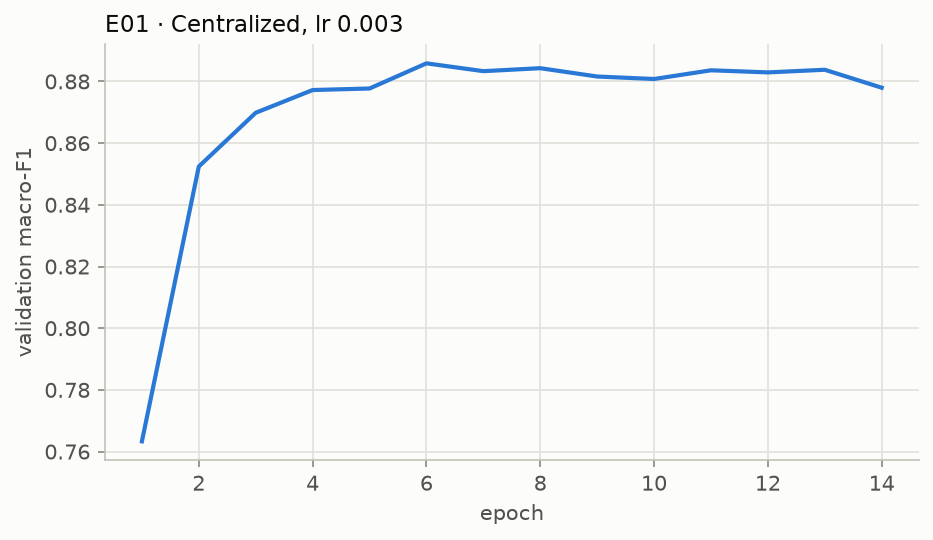

=== E02: Centralized, lr 0.01 ===
Goal: Pick the centralized learning rate (seed 0).
  1 run(s) to train: about 1 min at the speed measured so far
  central_lr0.01_ep14_seed0: training
    seed 0 | epoch   1/14 |    6.4 s | val loss 0.5294 | val macro-F1 0.86510
    seed 0 | epoch   5/14 |    6.4 s | val loss 1.0103 | val macro-F1 0.87830
    seed 0 | epoch  10/14 |    6.4 s | val loss 1.3152 | val macro-F1 0.88206
    seed 0 | epoch  14/14 |    6.4 s | val loss 1.4868 | val macro-F1 0.88215
E02 | test macro-F1 0.81188 | accuracy 0.88542 | false alarm rate 0.00143 | validation (selection) 0.88071 | target not set yet (it comes from E03)
  folder: C:\Users\srb13\Desktop\fyp\results\run_2026-11-09_2204\E02_centralized_lr_0.01


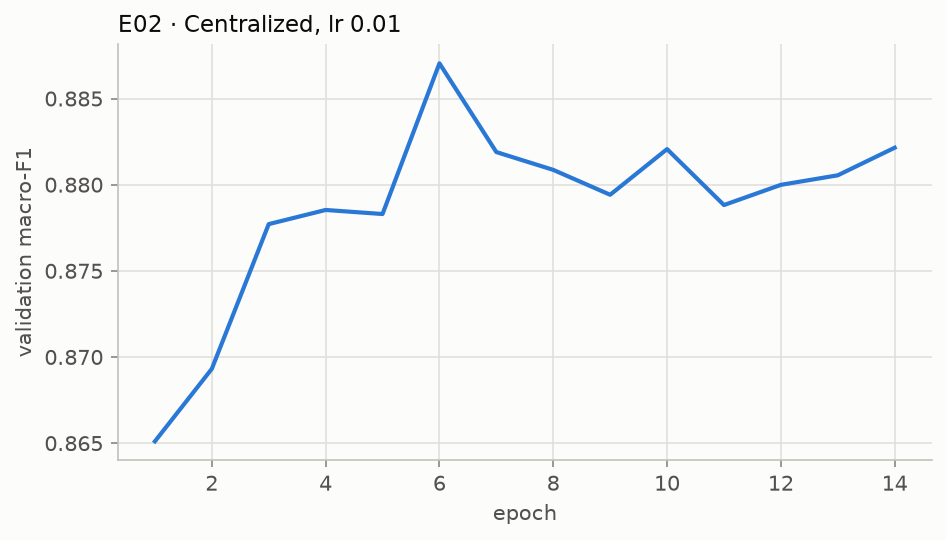

In [8]:
# E01, E02: centralized, one learning rate each (seed 0)
for k, lr in enumerate(CENTRAL_LRS):
    run_experiment(f"E{1 + k:02d}", f"Centralized, lr {lr}", "Pick the centralized learning rate (seed 0).",
                   group="central_search", method="centralized", lr=lr, seeds=[0])

Best centralized learning rate, by validation macro-F1 averaged over the last 5 epochs/rounds:
                            title  selection_score  chosen
experiment                                                
E01         Centralized, lr 0.003         0.881813    True
E02          Centralized, lr 0.01         0.880713   False
=== E03: Centralized reference, lr 0.003 ===
Goal: The reference quality and time per epoch; it sets the target.
  2 run(s) to train: about 3 min at the speed measured so far
  central_lr0.003_ep14_seed0: reused (already trained)
  central_lr0.003_ep14_seed1: training
    seed 1 | epoch   1/14 |    6.4 s | val loss 0.3816 | val macro-F1 0.74696
    seed 1 | epoch   5/14 |    6.4 s | val loss 0.3735 | val macro-F1 0.89304
    seed 1 | epoch  10/14 |    6.4 s | val loss 0.5662 | val macro-F1 0.89256
    seed 1 | epoch  14/14 |    6.4 s | val loss 0.6810 | val macro-F1 0.89307
  central_lr0.003_ep14_seed2: training
    seed 2 | epoch   1/14 |    6.4 s | val loss 0

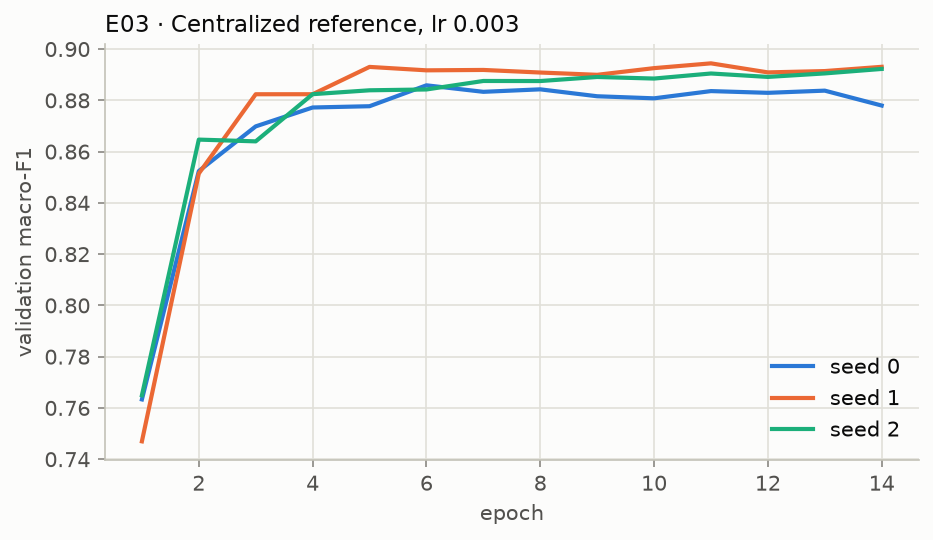

TARGET = 99% of E03's final validation macro-F1 (0.88776) = 0.87889


C:\Users\srb13\AppData\Local\Temp\ipykernel_20156\2957226888.py:223: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. The existing dtype int64 cannot hold the value being set, so the result has dtype float64. Cast the object to float64 before this operation to retain the current behavior.
  summary.loc["mean"] = per_seed.mean()


In [9]:
# E03: centralized reference with the best learning rate (3 seeds); it sets the target
BEST_CENTRAL = best_of([f"E{1 + k:02d}" for k in range(len(CENTRAL_LRS))], "centralized learning rate")
run_experiment("E03", f"Centralized reference, lr {BEST_CENTRAL['learning_rate']}",
               "The reference quality and time per epoch; it sets the target.",
               group="central_final", method="centralized", lr=BEST_CENTRAL["learning_rate"], seeds=SEEDS)
set_target("E03")

## Part B · FedAvg with the Part 7 settings (E04, E05)
1 local epoch per round, learning rate 0.01, 60 rounds, 3 seeds.
- **E04:** 9 IID clients (equal random shards). Any gap to E03 is the cost of federating alone.
- **E05:** one client per device (non-IID). Any extra gap is the cost of real device differences.

In [ ]:
# E04: FedAvg, 9 IID clients, Part 7 settings
run_experiment("E04", "FedAvg IID, Part 7 settings (E 1, lr 0.01)", "The cost of federating alone.",
               group="fedavg_default", method="fedavg", split="iid", local_epochs=1, lr=0.01, seeds=SEEDS)

=== E04: FedAvg IID, Part 7 settings (E 1, lr 0.01) ===
Goal: The cost of federating alone.
  3 run(s) to train: about 19 min at the speed measured so far
  iid_E1_lr0.01_mu0.0_R60_seed0: training


In [ ]:
# E05: FedAvg, one client per device (non-IID), Part 7 settings
run_experiment("E05", "FedAvg non-IID, Part 7 settings (E 1, lr 0.01)", "The extra cost of real device differences.",
               group="fedavg_default", method="fedavg", split="noniid", local_epochs=1, lr=0.01, seeds=SEEDS)

## Part C · FedAvg search on non-IID clients (E06–E11)
Six settings, one experiment each (seed 0, 60 rounds): local epochs E ∈ {1, 5, 10} × learning rate ∈ {0.003, 0.01}. More local epochs mean more work per round but also more drift away from the other clients, so every setting gets the same 60 rounds. E07 is E05's seed 0 (reused, not trained again).

In [ ]:
# E06-E11: FedAvg on non-IID clients, one setting each (seed 0)
for k, (local_epochs, lr) in enumerate(FEDAVG_SEARCH):
    run_experiment(f"E{6 + k:02d}", f"FedAvg non-IID search, E {local_epochs}, lr {lr}",
                   "Find the best FedAvg setting for non-IID clients (seed 0).",
                   group="fedavg_search", method="fedavg", split="noniid", local_epochs=local_epochs, lr=lr, seeds=[0])

## Part D · FedAvg with the best setting (E12, E13)
The setting with the best validation score in E06–E11, with 3 seeds.
- **E12:** non-IID clients, the final FedAvg result. Its seed 0 is the search run, so it is reused.
- **E13:** IID clients. Does the setting chosen for non-IID also work there?

In [ ]:
# E12: FedAvg non-IID with the best setting (3 seeds)
BEST_FEDAVG = best_of([f"E{6 + k:02d}" for k in range(len(FEDAVG_SEARCH))], "FedAvg setting")
E_BEST, LR_BEST = int(BEST_FEDAVG["local_epochs"]), BEST_FEDAVG["learning_rate"]
run_experiment("E12", f"FedAvg non-IID, best setting (E {E_BEST}, lr {LR_BEST})", "Final FedAvg result on non-IID clients.",
               group="fedavg_best", method="fedavg", split="noniid", local_epochs=E_BEST, lr=LR_BEST, seeds=SEEDS)

In [ ]:
# E13: FedAvg IID with the same setting (3 seeds)
run_experiment("E13", f"FedAvg IID, best setting (E {E_BEST}, lr {LR_BEST})",
               "Does the setting chosen for non-IID clients also work for IID clients?",
               group="fedavg_best", method="fedavg", split="iid", local_epochs=E_BEST, lr=LR_BEST, seeds=SEEDS)

## Part E · FedProx search on non-IID clients (E14–E17)
FedProx with the best FedAvg setting (same local epochs and learning rate) and μ ∈ {0.001, 0.01, 0.1, 1}, one experiment each (seed 0, 60 rounds). A larger μ pulls each client more strongly back toward the global model during its local epochs. The graph `overview_fedprox_search.png` also shows μ = 0 (FedAvg, E12's seed 0) for comparison.

In [ ]:
# E14-E17: FedProx on non-IID clients, one mu each (seed 0)
for k, mu in enumerate(FEDPROX_MUS):
    run_experiment(f"E{14 + k:02d}", f"FedProx non-IID search, mu {mu} (E {E_BEST}, lr {LR_BEST})",
                   "Find the best mu: does pulling clients toward the global model reduce drift? (seed 0)",
                   group="fedprox_search", method="fedprox", split="noniid",
                   local_epochs=E_BEST, lr=LR_BEST, mu=mu, seeds=[0])

## Part F · FedProx with the best μ (E18)
The μ with the best validation score in E14–E17, with 3 seeds (seed 0 is reused). Compare it with E12: same clients, local epochs and learning rate, and the only difference is the FedProx term.

In [ ]:
# E18: FedProx non-IID with the best mu (3 seeds)
BEST_FEDPROX = best_of([f"E{14 + k:02d}" for k in range(len(FEDPROX_MUS))], "FedProx mu")
MU_BEST = BEST_FEDPROX["mu"]
run_experiment("E18", f"FedProx non-IID, best mu {MU_BEST} (E {E_BEST}, lr {LR_BEST})",
               "Final FedProx result, to compare with E12.",
               group="fedprox_best", method="fedprox", split="noniid", local_epochs=E_BEST, lr=LR_BEST, mu=MU_BEST, seeds=SEEDS)

## 8. Summary of all experiments

In [ ]:
# 8. Summary of all experiments (also saved as summary_all_experiments.csv)
overview = update_overview()
shown = overview[["title", "seeds", "val_macro_f1_selection_mean", "test_macro_f1_mean", "test_macro_f1_std",
                  "test_false_alarm_rate_mean", "seeds_reaching_target", "epochs_or_rounds_to_target_mean",
                  "seconds_to_target_mean", "MB_to_target_mean", "training_seconds_total_mean", "MB_total_mean"]]
shown.columns = ["title", "seeds", "val (selection)", "test macro-F1", "± std", "false alarm rate", "seeds at target",
                 "epochs/rounds to target", "s to target", "MB to target", "training s", "MB sent"]
with pd.option_context("display.width", 260, "display.max_columns", 20, "display.max_colwidth", 60):
    print(shown.round(5).to_string())

choices = []
if "BEST_CENTRAL" in globals():
    choices.append(f"centralized lr {BEST_CENTRAL['learning_rate']}")
if "E_BEST" in globals():
    choices.append(f"FedAvg E {E_BEST}, lr {LR_BEST}")
if "MU_BEST" in globals():
    choices.append(f"FedProx mu {MU_BEST}")
print("\nChosen on validation:", " | ".join(choices) or "nothing yet")
print("Target:", "not set yet" if TARGET["value"] is None else f"{TARGET['value']:.5f}",
      "| training loop:", loop_name(), "| CUDA graph check, max weight difference:", GRAPH["max_difference"])
for name in ("overview_test_macro_f1.png", "overview_validation_curves.png",
             "overview_fedavg_search.png", "overview_fedprox_search.png"):
    if (RUN_DIR / name).exists():
        display(Image(filename=str(RUN_DIR / name)))
print("Everything is in", RUN_DIR.resolve())

## How to read the results
- **Main score: test macro-F1, not accuracy.** A quarter of the test set (gafgyt.tcp_udp) is one repeated row that every model gets right, so accuracy starts with a free 25%. Macro-F1 counts each class once, whatever its size.
- **Per class** (`per_class.csv`): read each class's F1 next to the share of its test rows already seen in training. `seen_unseen.csv` gives recall on those rows and on new rows. gafgyt.tcp_udp is essentially one repeated row, so its score shows that the model recognizes the flood, not that it generalizes.
- **Per device** (`per_device.csv`): devices 3 and 7 have no Mirai traffic, so their macro-F1 averages 5 classes.
- **Convergence:** the epochs or rounds, seconds and MB until validation first reaches the target (99% of E03's final validation macro-F1). FL seconds are the slowest client per round, as if the clients ran in parallel. Network time is not simulated, only bytes are counted.
- **Seeds:** ± is the standard deviation over seeds (with n − 1). A difference smaller than that spread is **not significant**.
- **Choices** were made on validation only (`selection_*.csv`). The test set never decided anything.
- **Time:** about a quarter of every training epoch is that one repeated flood row. It is the same for every method, so comparisons stay fair, but absolute times are inflated.
- **Data caveats** (decision 3): each file's row order is treated as its time order. The benign files are only mostly in order, and devices 3, 4, 6 and 7 include benign rows dated August 2018. For attack classes, the test set is the later part of the same recording, never a new attack. The 1% gap is shorter than the slowest window's memory for attacks. Packets shared across devices are assumed absent.

**Conclusions:** *(fill in after the run)*